# SEM basics · 3 — sources, receivers and records

Where the source is, what kind of source it is, what the receivers record, and
how several shots go into one call. Everything here works the same on the FD
`PropTorch`; the SEM-specific part is only how a point is put on the mesh.

1. **Positions** — grid indices `[ix, iz]`, fractional allowed
2. **Source types** — force, explosion and shear source on an elastic equation, and their radiation
3. **Receiver types** — components, derived velocities and the record layout
4. **Many shots in one call** — per-shot positions and wavelets, `(nshots, nt, nrec, ncomp)`

About 30 s on a GPU.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM
from sweep.sem.equations import ElasticSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

dh, n_order, f0 = 10.0, 4, 10.0
dt = 0.8e-3

device: cuda


## 1. Positions

Sources and receivers are **grid indices of the model**, column order `[ix, iz]`
in 2-D (`[ix, iy, iz]` in 3-D), exactly as on `PropTorch`; the absorbing layer is
outside and has no indices. The shapes:

| argument | shape | meaning |
| --- | --- | --- |
| `sources` | `(nshots, 2)` | one source per shot |
| `receivers` | `(nshots, nrec, 2)` or `(1, nrec, 2)` | per-shot spreads, or one spread for all shots |
| `wavelet` | `(nt,)` or `(nshots, nt)` | one wavelet for all shots, or one per shot |

A SEM mesh has no special points on the grid, so an index does not have to be an
integer: `PropSEM` finds the element that holds the point and the point's
position inside it, and injects or records through the element's basis
functions. `[40.5, 20.25]` is a valid source. Points inside the absorbing layer
are not (`PropSEM` warns).

A check: a vertical force, and receivers 400 m below it at every quarter cell
(2.5 m). In the P wave the ground moves along the ray, so `vx / vz` at the P
peak grows with the horizontal offset: a straight line through zero at the
source. Two shots, the source on a grid point (`ix = 60`) and halfway to the
next one (`ix = 60.5`):

source at ix = 60: vx/vz = 0 at x = 600.00 m
source at ix = 60.5: vx/vz = 0 at x = 604.98 m


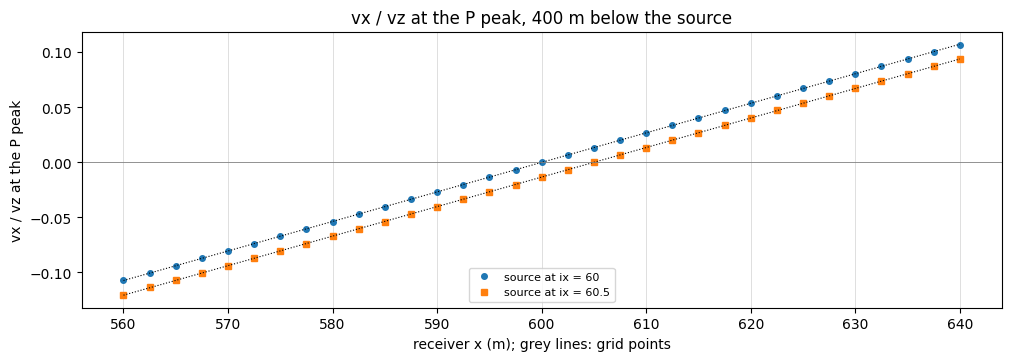

In [2]:
shape = (121, 121)                           # homogeneous, absorbing on all sides
vp  = torch.full(shape, 2000.0, device=device)
vs  = torch.full(shape, 1150.0, device=device)
rho = torch.full(shape, 2000.0, device=device)
nt, delay = 520, 0.12                        # ends before the S wave reaches the receivers
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[60.0, 60.0], [60.5, 60.0]])                 # (nshots, 2), fractional ix
rx = np.arange(56.0, 64.01, 0.25)                            # every quarter cell
rec = np.stack([rx, np.full_like(rx, 100.0)], axis=1)[None]  # 400 m below the sources

solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, f_dominant=f0, source_type=['vz'], receiver_type=['vx', 'vz'],
                 device=device)
with torch.no_grad():
    seis = solver(wavelet, src, rec, models=[vp, vs, rho]).cpu().numpy()
it_p = int(round((delay + 400.0 / 2000.0) / dt))            # the P peak below the source

fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
for s, mk in zip(range(2), 'os'):
    ratio = seis[s, it_p, :, 0] / seis[s, it_p, :, 1]
    slope, icpt = np.polyfit(rx * dh, ratio, 1)
    print(f'source at ix = {src[s, 0]:g}: vx/vz = 0 at x = {-icpt / slope:.2f} m')
    ax.plot(rx * dh, ratio, mk, ms=4, label=f'source at ix = {src[s, 0]:g}')
    ax.plot(rx * dh, np.polyval([slope, icpt], rx * dh), 'k:', lw=0.8)
for xg in np.arange(rx[0], rx[-1] + 1) * dh:
    ax.axvline(xg, color='0.85', lw=0.6, zorder=0)
ax.axhline(0, color='0.5', lw=0.6)
ax.set_xlabel('receiver x (m); grey lines: grid points')
ax.set_ylabel('vx / vz at the P peak')
ax.legend(fontsize=8); ax.set_title('vx / vz at the P peak, 400 m below the source')
plt.show()

Both shots give a straight line through every quarter-cell receiver (dotted: a
straight-line fit), with no steps at the grid points, and the zero crossing
moves with the source, to 605 m for `ix = 60.5`. A source or receivers moved to
the nearest grid point would give steps every 10 m instead.

## 2. Source types

On the elastic equations `source_type` takes the `PropTorch` names:

| `source_type` | source | the wavelet is |
| --- | --- | --- |
| `['vz']`, `['vx']` | a point force along z or x (the default is `['vz']`) | the force |
| `['sxx', 'szz']` | an explosion (moment tensor `Mxx = Mzz = 1`) | the moment rate |
| `['sxz']` | a shear source (`Mxz = Mzx = 1`) | the moment rate |

Each has its own radiation pattern. A homogeneous model, the source in the middle,
and one snapshot of the displacement 0.25 s after the wavelet's peak.
Snapshots need the eager backend (`impl='eager'`) and `return_wavefield=True`;
the next notebook has more on them.

In [3]:
shape = (121, 121)                           # 1.2 km x 1.2 km, absorbing on all sides
vp  = torch.full(shape, 2000.0, device=device)
vs  = torch.full(shape, 1150.0, device=device)
rho = torch.full(shape, 2000.0, device=device)
nt = 500
delay = 0.12
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
src = np.array([[60, 60]])
rec = np.array([[[60, 100]]])                # one receiver below the source
step = int(round((delay + 0.25) / dt))

snaps = {}
for stype in (['vz'], ['vx'], ['sxx', 'szz'], ['sxz']):
    solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                     abcn=40, f_dominant=f0, source_type=stype,
                     receiver_type=['vx', 'vz'], impl='eager', device=device)
    with torch.no_grad():
        seis, snap = solver(wavelet, src, rec, models=[vp, vs, rho],
                            return_wavefield=True, snapshot_times=[step])
    # (nsnap, nfield, nshots, 1, nz + 2 abcn, nx + 2 abcn): crop the absorbing layer
    snaps[', '.join(stype)] = snap[0, :, 0, 0, 40:-40, 40:-40].numpy()
print('snapshot fields:', solver.snapshot_fields, ' snapshot', tuple(snap.shape))

sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 121x121 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


snapshot fields: ['u_x', 'u_z']  snapshot (1, 2, 1, 1, 201, 201)


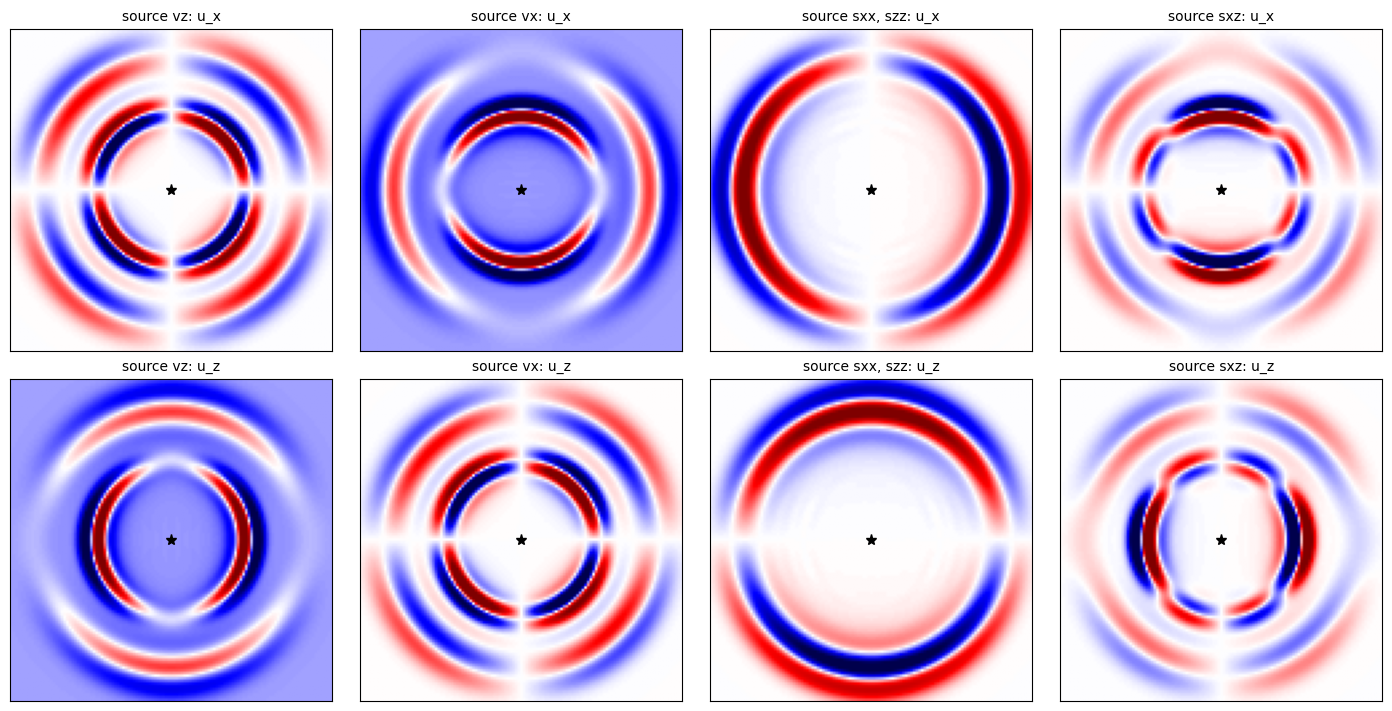

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
ext = [0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0]
for j, (name, s) in enumerate(snaps.items()):
    for i, comp in enumerate(['u_x', 'u_z']):
        img = s[i]
        lo, hi = np.percentile(img[img != 0], [1, 99])
        ax = axes[i, j]
        ax.imshow(img, cmap='seismic', vmin=lo, vmax=hi, extent=ext)
        ax.plot(src[0, 0] * dh, src[0, 1] * dh, 'k*', ms=8)
        ax.set_title(f'source {name}: {comp}', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
plt.show()

The outer ring is the P wave, the inner one the S wave. A vertical force sends
P mostly up and down and S mostly sideways; a horizontal force the opposite. The
explosion radiates P only, the same in every direction, and the shear source
four-lobed P and S. Both stress sources are stamped as a moment tensor in weak
form and driven with the wavelet's running integral, so the same `source_type`
and wavelet give the FD solver's waveform.

## 3. Receiver types

`receiver_type` lists the components to record; the record's last axis follows
that order. On the displacement equations (`ElasticSEM2DDeformed`) the native
fields are `u_x`, `u_z`, and `vx`, `vz` are their time derivatives, computed
from the traces for you. On the velocity–stress ones `vx`, `vz` are the fields
themselves. Recording both displacement and velocity from one run:

record (1, 750, 1, 2) = (nshots, nt, nrec, ncomp), ncomp = ['u_z', 'vz']


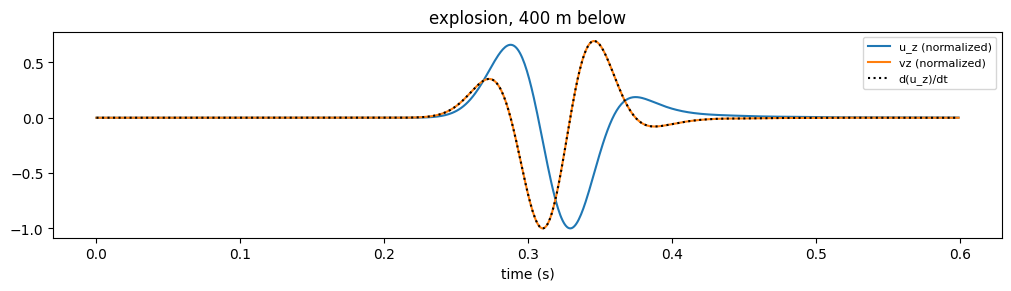

In [5]:
solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, f_dominant=f0, source_type=['sxx', 'szz'],
                 receiver_type=['u_z', 'vz'], device=device)
nt = 750                                     # long enough for the P wave to pass
wavelet = ricker(np.arange(nt) * dt - delay, f=f0).astype(np.float32)
with torch.no_grad():
    seis = solver(wavelet, src, rec, models=[vp, vs, rho])
print('record', tuple(seis.shape), '= (nshots, nt, nrec, ncomp), ncomp =', solver.receiver_type)

t = np.arange(nt) * dt
uz, vz = seis[0, :, 0, 0].cpu().numpy(), seis[0, :, 0, 1].cpu().numpy()
fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(t, uz / np.abs(uz).max(), label='u_z (normalized)')
ax.plot(t, vz / np.abs(vz).max(), label='vz (normalized)')
ax.plot(t, np.gradient(uz, dt) / np.abs(np.gradient(uz, dt)).max(), 'k:',
        label='d(u_z)/dt')
ax.set_xlabel('time (s)'); ax.legend(fontsize=8); ax.set_title('explosion, 400 m below')
plt.show()

## 4. Many shots in one call

Give `sources` one row per shot. Here three shots share one receiver spread
(`(1, nrec, 2)`) and each has its own wavelet (`(3, nt)`): the centre frequency
changes from shot to shot. On `impl='c'` the three shots run as one batched
kernel sequence, which is much faster than a loop over shots; the record has
one gather per shot.

In [6]:
shape = (97, 241)                                    # a two-layer model, free surface
vp  = torch.full(shape, 1800.0); vp[50:]  = 2600.0
vs  = torch.full(shape, 1000.0); vs[50:]  = 1500.0
rho = torch.full(shape, 2000.0); rho[50:] = 2200.0
models = [m.to(device) for m in (vp, vs, rho)]

nt = 1500
sources = np.array([[40, 10], [120, 10], [200, 10]])     # (nshots, 2)
rx = np.arange(0, shape[1], 2)
receivers = np.stack([rx, np.full_like(rx, 1)], axis=1)[None]   # (1, nrec, 2)
freqs = [6.0, 8.0, 10.0]
wavelets = np.stack([ricker(np.arange(nt) * dt - 1.2 / f, f=f) for f in freqs]
                    ).astype(np.float32)                  # (nshots, nt)

solver = PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=40, free_surface=True, f_dominant=10.0,
                 source_type=['sxx', 'szz'], receiver_type=['vx', 'vz'], device=device)
with torch.no_grad():
    seis = solver(wavelets, sources, receivers, models=models)
print('sources', sources.shape, ' receivers', receivers.shape, ' wavelets', wavelets.shape)
print('record', tuple(seis.shape), ' impl', solver.impl)

sources (3, 2)  receivers (1, 121, 2)  wavelets (3, 1500)
record (3, 1500, 121, 2)  impl c


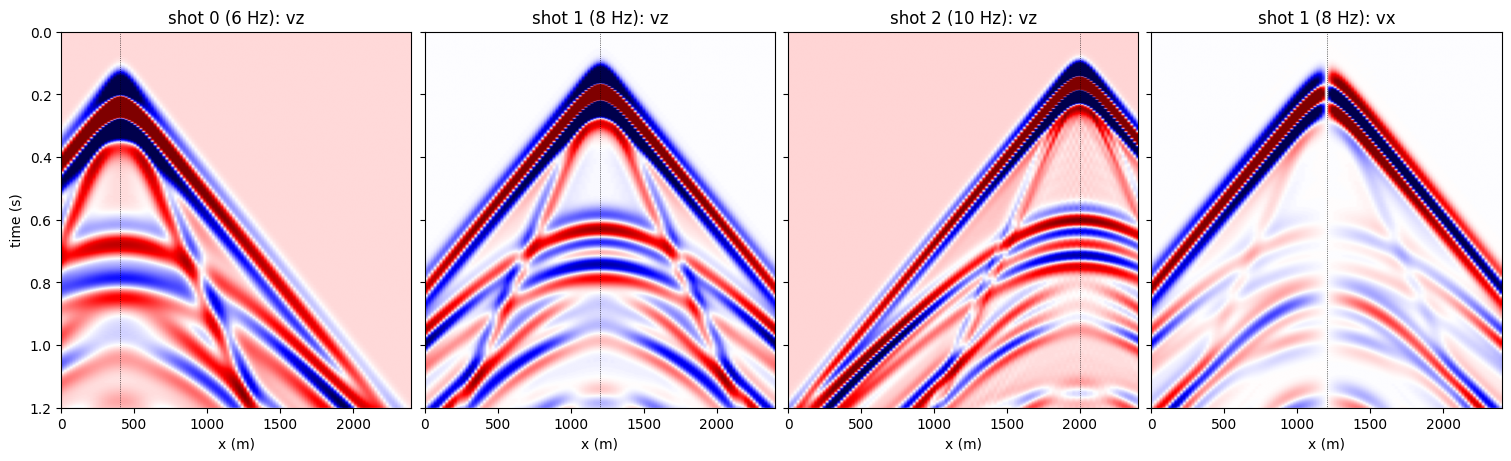

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), sharey=True, constrained_layout=True)
ext = [rx[0] * dh, rx[-1] * dh, nt * dt, 0]
panels = [(0, 1, 'shot 0 (6 Hz): vz'), (1, 1, 'shot 1 (8 Hz): vz'),
          (2, 1, 'shot 2 (10 Hz): vz'), (1, 0, 'shot 1 (8 Hz): vx')]
for ax, (s, c, title) in zip(axes, panels):
    g = seis[s, :, :, c].cpu().numpy()
    lo, hi = np.percentile(g[g != 0], [2, 98])
    ax.imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto', extent=ext)
    ax.axvline(sources[s, 0] * dh, color='k', lw=0.5, ls=':')
    ax.set_title(title); ax.set_xlabel('x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

## Summary

- `sources` `(nshots, ndim)`, `receivers` `(nshots, nrec, ndim)` or `(1, nrec, ndim)`,
  `wavelet` `(nt,)` or `(nshots, nt)`; indices `[ix, iz]` of the model grid,
  fractional allowed.
- `source_type`: `['vz']` / `['vx']` force, `['sxx', 'szz']` explosion, `['sxz']`
  shear (elastic); the acoustic equations take one pressure-like source.
- `receiver_type`: any of the equation's receiver fields and the derived `vx`,
  `vz` (and `p` on the acoustic potential form); the record is
  `(nshots, nt, nrec, len(receiver_type))`.

Next: [SEM basics · 4 — absorbing boundaries, free surfaces and snapshots](../53_sem_boundaries_and_snapshots/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="52_sem_sources_and_receivers.ipynb" download><code>52_sem_sources_and_receivers.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/52_sem_sources_and_receivers.ipynb">view on GitHub</a></p>